# 05 — Supplementary Analyses
## Part A: PCA, MCA, classical MDS and UMAP as alternative reductions. Part B: a short pulse-survey check for implementation

### Purpose
The main pipeline reduces the categorical survey responses with **multiple correspondence analysis (MCA)** for K-Means and uses **classical multidimensional scaling (MDS) of the Gower dissimilarity** for two-dimensional display. The **PCA** and **UMAP** are typical alternatives. This notebook tests, rather than assumes, that the choice made in Notebooks 03 and 04 is sound.

Part A answers four questions, all on the same 1,131 respondents and 15 items:

1. How much of the response structure does each linear representation retain (PCA on the indicator matrix versus MCA)?
2. Does clustering in a PCA space give a different partition from clustering in the MCA space?
3. Which two-dimensional view preserves local neighbourhoods best, measured by **trustworthiness** and **continuity** (Venna & Kaski, 2001) against the Gower dissimilarity?
4. Does a UMAP + HDBSCAN pipeline, a popular recipe, find dense groups that the Gower-based analysis did not?

Part B asks a practical implementation question: **how few of the 15 items would an organisation need to ask in order to reproduce the recommended segmentation?** (Section 7).

This notebook is supplementary. It does not change any Notebook 03 or 04 result.

## 1. Imports, configuration and inputs

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap

from hdbscan import HDBSCAN
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score
from sklearn.metrics import adjusted_rand_score, silhouette_score

RANDOM_STATE = 42
K_NEIGHBOURS = 15                 # neighbourhood size for trustworthiness / continuity
K_CURVE = [5, 10, 15, 25, 40, 60]
UMAP_PARAMS = {"n_neighbors": 15, "min_dist": 0.1}

HERE = Path.cwd().resolve()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
PROCESSED = ROOT / "data" / "processed"
EVAL_DIR = ROOT / "reports" / "results" / "model_evaluation"
RESULTS_DIR = ROOT / "reports" / "results" / "supplementary_dimensionality"
FIGURES_DIR = ROOT / "reports" / "figures" / "supplementary_dimensionality"

for d in (RESULTS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

Z = pd.read_csv(
    PROCESSED / "osmi_2016_mca_indicator_matrix.csv"
).to_numpy(dtype=float)
D = np.asarray(
    np.load(PROCESSED / "osmi_2016_gower_dissimilarity.npy"),
    dtype=np.float64
)
D = np.clip((D + D.T) / 2.0, 0.0, 1.0)

np.fill_diagonal(D, 0.0)

meta = json.loads(
    (PROCESSED / "osmi_2016_preparation_metadata.json")
    .read_text(encoding="utf-8")
)
assignments = pd.read_csv(
    EVAL_DIR / "osmi_2016_recommended_cluster_assignments.csv"
).sort_values("model_row_index")

reference = assignments["cluster_label"].to_numpy()
model_key = assignments["model_key"].iloc[0]

N, Q = Z.shape[0], int(meta["primary_feature_count"])

assert N == 1131 and D.shape == (N, N) and len(reference) == N
assert (reference != -1).all(), (
    "The reference partition is expected to cover every respondent."
)

print(
    f"Respondents: {N}; indicator columns: {Z.shape[1]}; "
    f"reference partition: {model_key} "
    f"with sizes {np.bincount(reference).tolist()}"
)

Respondents: 1131; indicator columns: 52; reference partition: MCA + K-Means with sizes [607, 524]


## 2. Linear representations: PCA versus MCA

PCA is applied to the **centred indicator matrix** (the usual way PCA is applied to dummy-coded survey data). MCA is the correspondence-analysis counterpart: it weights respondents and categories by their frequencies, so that Euclidean distance between respondents equals the χ² distance between response profiles. PCA ignores those weights, which lets frequent categories dominate the variance. MCA's *raw* inertia percentages are known to understate the quality of a solution, so the Benzécri/Greenacre-adjusted rates are reported next to PCA's explained variance.

In [2]:
def mca_fit(Z_in: np.ndarray, n_comp: int | None = None):
    n_rows, q_cols = Z_in.shape
    P = Z_in / (n_rows * Q)
    r, c = P.sum(axis=1), P.sum(axis=0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, s, Vt = np.linalg.svd(S, full_matrices=False)
    n_nontrivial = q_cols - Q
    s, U = s[:n_nontrivial], U[:, :n_nontrivial]
    eig = s ** 2

    if n_comp is None:
        n_comp = max(int(np.sum(eig > 1 / Q)), 2)             # eigenvalue > 1/Q rule (as in Notebook 03)

    coords = U[:, :n_comp] * s[:n_comp] / np.sqrt(r)[:, None]
    adj = np.where(eig > 1 / Q, ((Q / (Q - 1)) * (eig - 1 / Q)) ** 2, 0.0)
    greenacre_total = (Q / (Q - 1)) * (np.sum(eig ** 2) - (q_cols - Q) / Q ** 2)

    return coords, eig, adj / greenacre_total, n_comp


mca_coords, mca_eig, mca_adj, N_COMP = mca_fit(Z)
pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE).fit(Z)
pca_coords = pca.transform(Z)

variance_table = pd.DataFrame({
    "dimension": np.arange(1, N_COMP + 1),
    "pca_explained_variance_pct": pca.explained_variance_ratio_ * 100,
    "mca_raw_inertia_pct": mca_eig[:N_COMP] / mca_eig.sum() * 100,
    "mca_adjusted_inertia_pct": mca_adj[:N_COMP] * 100,
})
variance_table["pca_cumulative_pct"] = variance_table["pca_explained_variance_pct"].cumsum()
variance_table["mca_raw_cumulative_pct"] = variance_table["mca_raw_inertia_pct"].cumsum()
variance_table["mca_adjusted_cumulative_pct"] = variance_table["mca_adjusted_inertia_pct"].cumsum()
variance_table.to_csv(RESULTS_DIR / "pca_vs_mca_variance.csv", index=False)

display(variance_table.round(2))
print(
    f"Retained dimensions (eigenvalue > 1/Q): {N_COMP}. "
    f"PCA cumulative variance: {variance_table['pca_cumulative_pct'].iloc[-1]:.1f}%; "
    f"MCA raw: {variance_table['mca_raw_cumulative_pct'].iloc[-1]:.1f}%; "
    f"MCA adjusted: {variance_table['mca_adjusted_cumulative_pct'].iloc[-1]:.1f}%."
)

,dimension,pca_explained_variance_pct,mca_raw_inertia_pct,mca_adjusted_inertia_pct,pca_cumulative_pct,mca_raw_cumulative_pct,mca_adjusted_cumulative_pct
0,1,15.18,12.43,69.92,15.18,12.43,69.92
1,2,8.10,6.21,9.08,23.29,18.64,79.00
2,3,6.37,4.96,3.76,29.65,23.60,82.76
3,4,5.20,4.18,1.61,34.86,27.78,84.37
4,5,4.81,3.93,1.11,39.67,31.71,85.48
5,6,4.21,3.70,0.74,43.87,35.41,86.21
6,7,3.88,3.48,0.45,47.75,38.89,86.66
7,8,3.69,3.42,0.38,51.45,42.31,87.04
8,9,3.47,3.11,0.12,54.92,45.42,87.17
9,10,3.43,3.07,0.10,58.34,48.50,87.27


Retained dimensions (eigenvalue > 1/Q): 14. PCA cumulative variance: 70.3%; MCA raw: 59.6%; MCA adjusted: 87.3%.


## 3. Does the reduction change the clustering?

K-Means with k = 2 (the recommended setting) is run on the first `N_COMP` PCA components and on the MCA coordinates, with 20 starts each. Agreement with the recommended partition is measured by the adjusted Rand index (Hubert & Arabie, 1985); separation by the common Gower silhouette, which is defined independently of either space.

In [3]:
def kmeans_labels(coords: np.ndarray, k: int = 2) -> np.ndarray:
    return KMeans(
        n_clusters=k,
        n_init=20,
        random_state=RANDOM_STATE
    ).fit_predict(coords)


rows = []
for name, coords in {
    "PCA (centred indicator matrix)": pca_coords,
    "MCA (reference)": mca_coords
}.items():
    labels = kmeans_labels(coords)
    rows.append({
        "representation": name,
        "dimensions": coords.shape[1],
        "ari_vs_reference": adjusted_rand_score(reference, labels),
        "gower_silhouette": silhouette_score(
            D,
            labels,
            metric="precomputed"
        ),
        "cluster_sizes": np.bincount(labels).tolist(),
    })

clustering_comparison = pd.DataFrame(rows)
display(clustering_comparison.round(3))
clustering_comparison.to_csv(
    RESULTS_DIR / "pca_vs_mca_kmeans.csv",
    index=False
)

,representation,dimensions,ari_vs_reference,gower_silhouette,cluster_sizes
0,PCA (centred indicator matrix),14,0.857,0.203,"[623, 508]"
1,MCA (reference),14,0.993,0.200,"[609, 522]"


## 4. Two-dimensional views and neighbourhood preservation

Four two-dimensional views are built: the first two PCA components, the first two MCA dimensions, classical (Torgerson) MDS of the Gower dissimilarity, and UMAP (McInnes et al., 2018) on the precomputed Gower dissimilarity.

**Trustworthiness** T(k) penalises *false neighbours*, points that appear close in the plot but are not close in the original data. **Continuity** C(k) penalises *torn neighbourhoods*, points that are close in the original data but far apart in the plot (Venna & Kaski, 2001). Both equal 1 for a perfect embedding. They are computed here directly from rank matrices, against the Gower dissimilarity as the original space. Gower distances between respondents take few distinct values (the items are coarse categories), so rank ties are common and are broken by a stable sort and the scores should be read as relative, not absolute, evidence.

In [5]:
def classical_mds(Dm: np.ndarray, dims: int = 2) -> np.ndarray:
    n_ = Dm.shape[0]
    J = np.eye(n_) - np.ones((n_, n_)) / n_
    B = -0.5 * J @ (Dm ** 2) @ J
    vals, vecs = np.linalg.eigh(B)
    idx = np.argsort(vals)[::-1][:dims]
    return vecs[:, idx] * np.sqrt(np.maximum(vals[idx], 0))


def pairwise_euclidean(X: np.ndarray) -> np.ndarray:
    sq = (X ** 2).sum(axis=1)
    return np.sqrt(
        np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0.0)
    )


def rank_matrix(Dm: np.ndarray) -> np.ndarray:
    """rank[i, j] = position of j in the ordering of distances from i (self = 0)."""
    order = np.argsort(Dm, axis=1, kind="stable")
    ranks = np.empty_like(order)
    rows_ = np.arange(Dm.shape[0])[:, None]
    ranks[rows_, order] = np.arange(Dm.shape[0])[None, :]
    return ranks


def trust_continuity(
    D_orig: np.ndarray,
    D_emb: np.ndarray,
    ks
) -> pd.DataFrame:
    n_ = D_orig.shape[0]
    r_orig, r_emb = rank_matrix(D_orig), rank_matrix(D_emb)
    out = []

    for k in ks:
        norm = 2.0 / (n_ * k * (2 * n_ - 3 * k - 1))
        in_emb = (r_emb >= 1) & (r_emb <= k)
        in_orig = (r_orig >= 1) & (r_orig <= k)
        false_nb = in_emb & ~in_orig          # close in the plot, not in the data
        torn_nb = in_orig & ~in_emb           # close in the data, not in the plot
        t = 1 - norm * np.sum((r_orig - k)[false_nb])
        c = 1 - norm * np.sum((r_emb - k)[torn_nb])
        out.append({
            "k": k,
            "trustworthiness": float(t),
            "continuity": float(c)
        })
    return pd.DataFrame(out)


embeddings = {
    "PCA": pca_coords[:, :2],
    "MCA": mca_coords[:, :2],
    "Classical MDS (Gower)": classical_mds(D),
    "UMAP (Gower)": umap.UMAP(
        n_components=2,
        metric="precomputed",
        random_state=RANDOM_STATE,
        **UMAP_PARAMS
    ).fit_transform(D),
}
# The retained MCA space used for clustering is shown 
# as a reference for how much the 2-D step loses.
spaces = {
    **embeddings,
    f"MCA ({N_COMP}-D, used for clustering)": mca_coords
}

tc_rows = []
for name, coords in spaces.items():
    curve = trust_continuity(
        D,
        pairwise_euclidean(coords),
        K_CURVE
    )
    curve.insert(0, "view", name)
    tc_rows.append(curve)

tc_all = pd.concat(tc_rows, ignore_index=True)
tc_summary = tc_all[
    tc_all["k"] == K_NEIGHBOURS
].set_index("view")[
    ["trustworthiness", "continuity"]
]
display(tc_summary.round(3))

tc_all.to_csv(
    RESULTS_DIR / "trustworthiness_continuity.csv",
    index=False
)
emb_out = pd.concat(
    [
        pd.DataFrame(xy, columns=["x", "y"])
        .assign(
            view=name,
            model_row_index=np.arange(N),
            cluster_label=reference
        )
        for name, xy in embeddings.items()
    ],
    ignore_index=True
)
emb_out.to_csv(
    RESULTS_DIR / "two_dimensional_embeddings.csv",
    index=False
)

c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\.venv\Lib\site-packages\umap\umap_.py:3002: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\User\Documents\Projects\osmi-mental-health-data-clustering\.venv\Lib\site-packages\umap\umap_.

,trustworthiness,continuity
view,,
PCA,0.771,0.877
MCA,0.766,0.865
Classical MDS (Gower),0.782,0.892
UMAP (Gower),0.921,0.913
"MCA (14-D, used for clustering)",0.948,0.955


## 5. UMAP + HDBSCAN: a cautionary check

UMAP is often followed by a density-based clusterer. HDBSCAN is run here on the two-dimensional UMAP embedding with a grid of `min_cluster_size` values, and the groups it finds are compared with the recommended partition. UMAP deliberately concentrates points into compact islands, so dense-looking groups in its output are not independent evidence of natural clusters. The reference is the Gower-based HDBSCAN grid of Notebook 03, which found no qualifying density structure.

In [6]:
rows = []
for mcs in (15, 25, 40, 60):
    labels = HDBSCAN(
        min_cluster_size=mcs, min_samples=5
    ).fit_predict(embeddings["UMAP (Gower)"])
    assigned = labels != -1
    n_clusters = len(set(labels[assigned]))
    rows.append({
        "min_cluster_size": mcs,
        "n_clusters": n_clusters,
        "noise_share": float((~assigned).mean()),
        "ari_vs_reference_on_clustered": (
            adjusted_rand_score(
                reference[assigned],
                labels[assigned]
            )
            if n_clusters >= 2 else np.nan
        ),
        "gower_silhouette": (
            silhouette_score(
                D[np.ix_(assigned, assigned)],
                labels[assigned],
                metric="precomputed"
            )
            if n_clusters >= 2 else np.nan
        ),
    })
    
umap_hdbscan = pd.DataFrame(rows)
display(umap_hdbscan.round(3))

umap_hdbscan.to_csv(
    RESULTS_DIR / "umap_hdbscan_check.csv",
    index=False
)

,min_cluster_size,n_clusters,noise_share,ari_vs_reference_on_clustered,gower_silhouette
0,15,18,0.267,0.115,0.110
1,25,13,0.279,0.150,0.124
2,40,5,0.208,0.253,0.124
3,60,5,0.208,0.253,0.124


## 6. Figures (Part A)

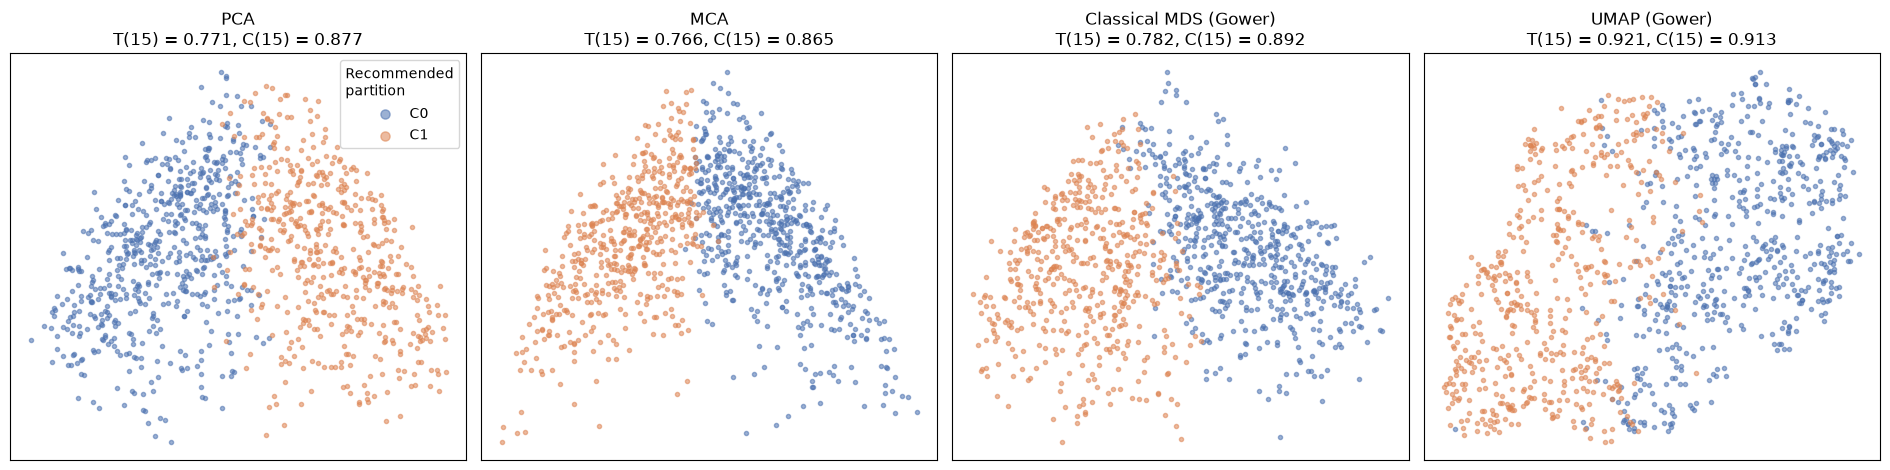

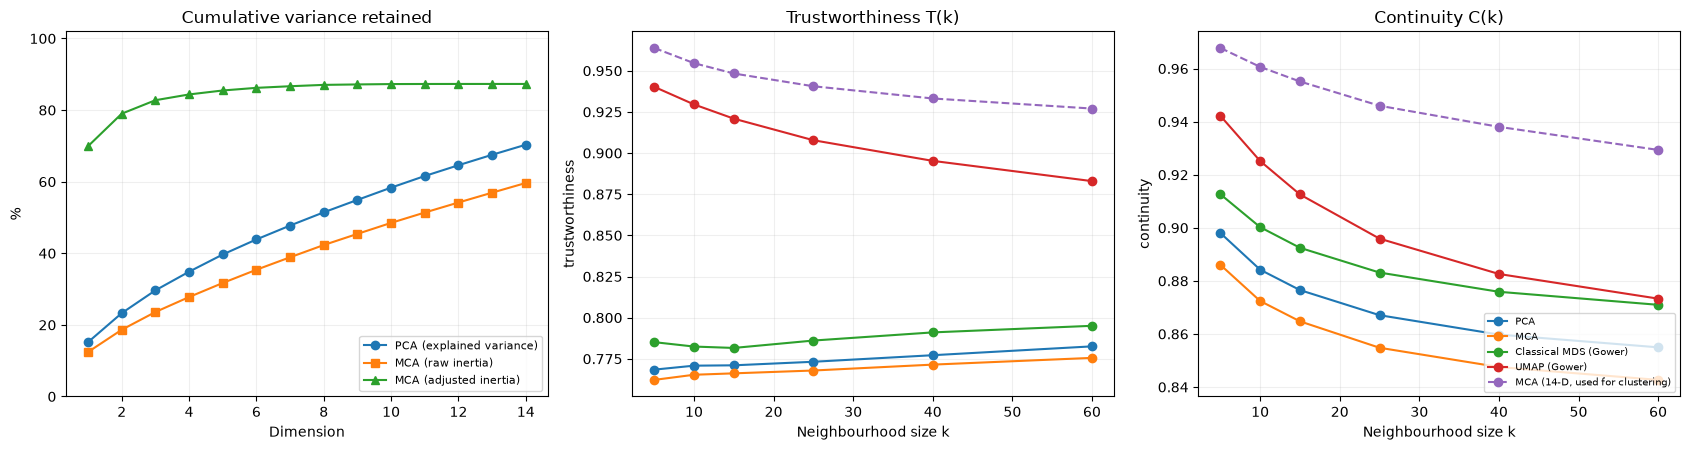

In [7]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=250, bbox_inches="tight")
    plt.show()


palette = {0: "#4c72b0", 1: "#dd8452"}
rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, (name, xy) in zip(axes, embeddings.items()):
    jitter = rng.normal(scale=0.012, size=xy.shape) * np.ptp(xy, axis=0)      # discrete distances cause overplotting

    for c in sorted(np.unique(reference)):
        ax.scatter(
            *(xy + jitter)[reference == c].T,
            s=9,
            alpha=0.55,
            color=palette[int(c)],
            label=f"C{c}"
        )

    t, c_ = tc_summary.loc[name, "trustworthiness"], tc_summary.loc[name, "continuity"]
    ax.set(
        title=f"{name}\nT(15) = {t:.3f}, C(15) = {c_:.3f}",
        xticks=[],
        yticks=[]
    )
    ax.grid(False)

axes[0].legend(markerscale=2.2, title="Recommended\npartition")
save(fig, "two_dimensional_views.png")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(1, N_COMP + 1)

axes[0].plot(
    x,
    variance_table["pca_cumulative_pct"],
    marker="o",
    label="PCA (explained variance)"
)
axes[0].plot(
    x,
    variance_table["mca_raw_cumulative_pct"],
    marker="s",
    label="MCA (raw inertia)"
)
axes[0].plot(
    x,
    variance_table["mca_adjusted_cumulative_pct"],
    marker="^",
    label="MCA (adjusted inertia)"
)
axes[0].set(
    title="Cumulative variance retained",
    xlabel="Dimension",
    ylabel="%",
    ylim=(0, 102)
)
axes[0].legend(fontsize=8)

for ax, col, title in zip(
    axes[1:],
    ["trustworthiness", "continuity"],
    ["Trustworthiness T(k)", "Continuity C(k)"]
):
    for name in spaces:
        sub = tc_all[tc_all["view"] == name]
        ax.plot(
            sub["k"],
            sub[col],
            marker="o",
            label=name,
            linestyle="--" if name.startswith("MCA (") else "-"
        )

    ax.set(title=title, xlabel="Neighbourhood size k", ylabel=col)

axes[2].legend(fontsize=7, loc="lower right")

for ax in axes:
    ax.grid(alpha=0.2)
    
save(fig, "variance_and_neighbourhood_preservation.png")

## 7. Part B: how short can a pulse survey be?

An organisation that wanted to monitor the two response patterns would not want to ask 15 questions every time. Items are ranked by their bias-corrected Cramér's V with the recommended partition (Notebook 04), and for the top *m* items a multinomial logistic regression is cross-validated (repeated stratified 10-fold) to see how well the 15-item partition can be **reconstructed** from those items alone. This is a reconstruction check, not an external validation: the labels were themselves derived from the same items, so the result shows how redundant the items are, not whether the clusters are real.

,items,accuracy,accuracy_sd,balanced_accuracy,cohen_kappa
0,1,0.864,0.031,0.857,0.723
1,2,0.889,0.027,0.888,0.776
2,3,0.902,0.025,0.900,0.802
3,5,0.926,0.021,0.924,0.850
4,7,0.940,0.017,0.940,0.880
5,10,0.965,0.015,0.965,0.930
6,15,0.983,0.011,0.983,0.966


Majority-class baseline accuracy: 0.537


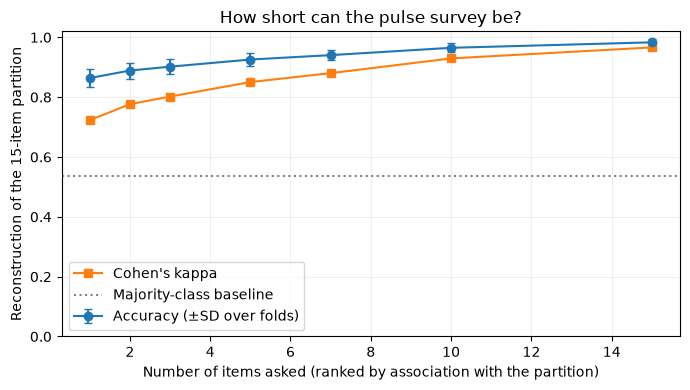

In [8]:
features = meta["primary_features"]
kmodes_in = pd.read_csv(
    PROCESSED / "osmi_2016_kmodes_input.csv",
    dtype="string"
)
assoc = pd.read_csv(EVAL_DIR / "osmi_2016_item_association.csv")
ranking = (
    assoc[assoc["model_key"] == model_key]
    .sort_values("cramers_v", ascending=False)["feature"].tolist()
)

assert set(ranking) == set(features)

cv = RepeatedStratifiedKFold(
    n_splits=10,
    n_repeats=3,
    random_state=RANDOM_STATE
)

rows = []
for m in (1, 2, 3, 5, 7, 10, 15):
    cols = ranking[:m]
    X_m = pd.get_dummies(kmodes_in[cols].astype(str)).to_numpy(dtype=float)
    accs, bals, kappas = [], [], []
    for rep, (train_idx, test_idx) in enumerate(cv.split(X_m, reference)):
        clf = LogisticRegression(max_iter=2000, C=1.0).fit(
            X_m[train_idx],
            reference[train_idx]
        )
        pred = clf.predict(X_m[test_idx])
        accs.append((pred == reference[test_idx]).mean())
        bals.append(balanced_accuracy_score(reference[test_idx], pred))
        kappas.append(cohen_kappa_score(reference[test_idx], pred))

    rows.append({
        "items": m,
        "accuracy": np.mean(accs),
        "accuracy_sd": np.std(accs, ddof=1),
        "balanced_accuracy": np.mean(bals),
        "cohen_kappa": np.mean(kappas),
        "items_used": ", ".join(cols)
    })

pulse = pd.DataFrame(rows)
majority = max(np.bincount(reference)) / len(reference)

display(pulse.drop(columns="items_used").round(3))
print(f"Majority-class baseline accuracy: {majority:.3f}")

pulse.to_csv(
    RESULTS_DIR / "pulse_survey_reconstruction.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    pulse["items"],
    pulse["accuracy"],
    yerr=pulse["accuracy_sd"],
    marker="o",
    capsize=3,
    label="Accuracy (±SD over folds)"
)
ax.plot(pulse["items"], pulse["cohen_kappa"], marker="s", label="Cohen's kappa")
ax.axhline(majority, color="grey", linestyle=":", label="Majority-class baseline")
ax.set(
    xlabel="Number of items asked (ranked by association with the partition)",
    ylabel="Reconstruction of the 15-item partition",
    title="How short can the pulse survey be?", ylim=(0, 1.02)
)
ax.legend(); ax.grid(alpha=0.2)
save(fig, "pulse_survey_reconstruction.png")

## 8. Interpretation and findings

### 8.1 Linear representations and clustering

The eigenvalue rule retained **14 dimensions** for both representations. Across those dimensions, PCA retained **70.33%** cumulative explained variance. MCA retained **59.64%** cumulative raw inertia; after the reported Benzécri/Greenacre adjustment, the cumulative MCA rate was **87.30%**. The raw MCA percentage is therefore not an appropriate stand-alone basis for judging the MCA solution: the adjusted result gives a materially different account of the inertia represented. These adjusted MCA rates and PCA explained-variance rates are different quantities, so the percentages should not be treated as a direct like-for-like contest.

The clustering comparison is more decisive. K-Means in the 14-dimensional PCA space achieved an **ARI of 0.857** against the recommended partition, while K-Means in the 14-dimensional MCA space achieved **0.993**. The MCA result is almost identical to the reference partition; the PCA result is strongly aligned but not identical. Their Gower silhouettes were **0.200 (MCA)** and **0.203 (PCA)**, respectively. The negligible silhouette difference does not indicate that PCA produces better-separated groups. Both values indicate only modest separation in the original Gower dissimilarity, despite the high agreement between partitions. The resulting sizes were 609/522 for MCA and 623/508 for PCA.

Taken together, these results show that the recommended partition is highly reproducible in the MCA representation. PCA broadly recovers the same two-way structure, but changes a meaningful subset of assignments and offers no material improvement in Gower separation.

### 8.2 Two-dimensional neighbourhood preservation

At the reported neighbourhood size of **k = 15**, UMAP on Gower dissimilarities had the strongest scores among the four two-dimensional views: **trustworthiness = 0.921** and **continuity = 0.913**. Classical MDS scored **0.782 / 0.892**, PCA scored **0.771 / 0.877**, and the two-dimensional MCA view scored **0.766 / 0.865** (trustworthiness / continuity).

UMAP therefore provides the most faithful two-dimensional display of local Gower neighbourhoods among the plotted alternatives. Its scores are not perfect, and the result is specific to the selected UMAP settings and neighbourhood size. The retained **14-dimensional MCA space** scored **0.948 / 0.955**, higher than every two-dimensional view. This confirms that compressing the MCA representation to two dimensions loses neighbourhood information; the two-dimensional plots are visual summaries, not substitutes for the higher-dimensional space used for clustering.

The rank-based scores are relative evidence. Gower distances contain many ties because the input consists of categorical responses, and the notebook resolves ties using a stable sort. Small differences between the PCA, MCA and MDS scores should consequently not be over-interpreted.

### 8.3 UMAP followed by HDBSCAN

HDBSCAN on the two-dimensional UMAP embedding returned **18 clusters** at `min_cluster_size=15`, **13 clusters** at 25, and **5 clusters** at both 40 and 60. The corresponding noise shares were **26.7%, 27.9%, 20.8% and 20.8%**. Agreement with the recommended partition remained low: ARI values were **0.115, 0.150 and 0.253** (the latter value for both settings). Gower silhouettes were also low, ranging from **0.110 to 0.124**.

The denser-looking UMAP regions therefore do not reproduce the recommended two-group partition. Increasing the minimum cluster size reduces the number of detected groups, but does not produce strong agreement or convincing separation in the original Gower space. These results do not provide evidence for replacing the recommended partition with the multiple density-based groups found in the UMAP embedding. They are consistent with the earlier Gower-based HDBSCAN check, which found no qualifying density structure.

### 8.4 Pulse-survey reconstruction

The repeated stratified 10-fold evaluation shows that a small subset of the association-ranked items can reconstruct the 15-item reference labels with high predictive performance. The majority-class baseline accuracy was **0.537**. With the top-ranked items, accuracy was **0.864 using 1 item**, **0.889 using 2**, **0.902 using 3**, **0.926 using 5**, **0.940 using 7**, **0.965 using 10**, and **0.983 using all 15**.

Balanced accuracy followed the same pattern, increasing from **0.857 with 1 item** to **0.924 with 5**, **0.940 with 7**, **0.965 with 10**, and **0.983 with 15**. Cohen's kappa increased from **0.723 with 1 item** to **0.850 with 5**, **0.880 with 7**, **0.930 with 10**, and **0.966 with 15**. The fold-level accuracy standard deviation declined from **0.031** for one item to **0.021** for five, **0.017** for seven and **0.011** for all 15, indicating increasingly consistent reconstruction across folds.

The results show a clear trade-off between survey length and reconstruction fidelity. Five items already reproduce the reference labels at 92.6% accuracy, while seven reach 94.0%; ten reach 96.5%. This is evidence that the reference partition is highly compressible from the association-ranked items. It is **not independent validation of the segmentation**: the reference labels were originally derived from the same 15-item response set, and the pulse model is trained to predict those derived labels. High accuracy demonstrates redundancy and reconstructability within these data, not that the two groups are natural, stable or externally meaningful respondent types.

### 8.5 Overall conclusion

The supplementary analyses support the existing analytical choices without establishing stronger cluster validity. MCA most faithfully reproduces the recommended partition; PCA gives a similar but not identical result. UMAP is the strongest two-dimensional neighbourhood-preserving display, while the full 14-dimensional MCA representation preserves neighbourhoods better still. UMAP-HDBSCAN produces several weakly separated groups that do not align well with the recommended partition. Finally, a five- to seven-item pulse survey reconstructs the existing labels well, but that efficiency result must not be presented as external validation.

Accordingly, the supplementary evidence supports retaining the **MCA-based two-cluster solution** as the analytical reference, using **Gower-based MDS** for continuity with the main pipeline and **UMAP** as an additional visualisation, and treating the pulse-survey result strictly as a reconstruction/implementation finding. None of these supplementary checks removes the need for external validation before the two clusters are interpreted as generalisable respondent segments.